# Лабораторная работа 2. Сжатие изображений (JPEG)

Здесь реализован компрессор по мотивам JPEG: RGB → YCbCr, децимация цветоразностных каналов, ДКП на блоках 8×8, квантование с параметром качества, зигзаг-обход, разностное кодирование DC, RLE и кодирование переменной длины для AC, кодирование Хаффмана по таблицам стандарта ITU-T T.81. Запускать нужно сверху вниз.

Перед запуском положите рядом с ноутбуком `Lena.png` (512×512) и своё цветное изображение не меньше 512×512 (имя укажите в `COLOR_FILE`).

## __Задание 1__

#### 1. Тестовые данные

Lena : (512, 512)
Цвет : (512, 512)


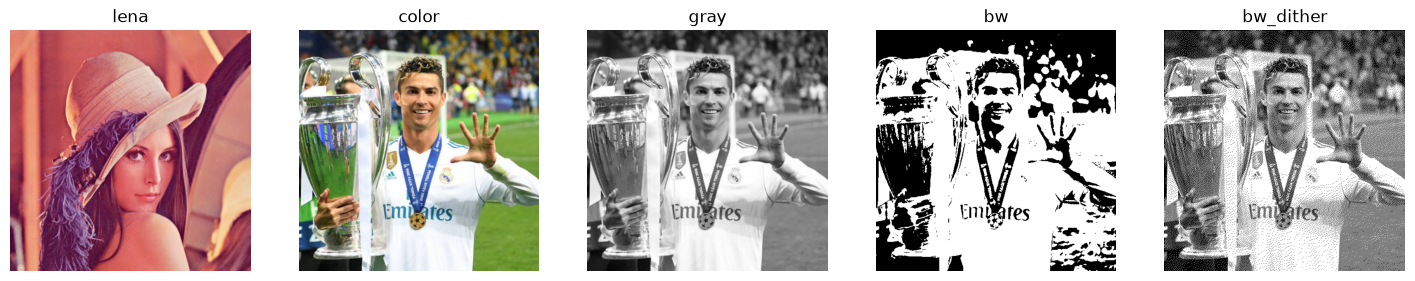

In [1]:
import os, math, bisect, struct, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ==================================================
# НАСТРОЙКИ
# ==================================================

LENA_FILE = "Lena.png"
COLOR_FILE = "color.jpg"      # своё цветное изображение, не меньше 512x512

TEST_DIR = "test_images"
COMPRESSED_DIR = "compressed"
RESTORED_DIR = "restored"

for folder in (TEST_DIR, COMPRESSED_DIR, RESTORED_DIR):
    os.makedirs(folder, exist_ok=True)


# ==================================================
# ТЕСТОВЫЕ ИЗОБРАЖЕНИЯ
# ==================================================

lena = Image.open(LENA_FILE).convert("RGB")
color = Image.open(COLOR_FILE).convert("RGB")

print("Lena :", lena.size)
print("Цвет :", color.size)

# оттенки серого - конвертация цветного изображения
gray = color.convert("L")

# чёрно-белое без дизеринга: c' = round(c / 255) * 255
gray_array = np.array(gray)
bw_array = (np.round(gray_array / 255) * 255).astype(np.uint8)
bw = Image.fromarray(bw_array).convert("1", dither=Image.Dither.NONE)

# чёрно-белое с дизерингом (Флойд-Стейнберг)
bw_dither = gray.convert("1")

test_images = {
    "lena": lena,
    "color": color,
    "gray": gray,
    "bw": bw,
    "bw_dither": bw_dither,
}

TEST_FILES = {}

for name, image in test_images.items():

    path = os.path.join(TEST_DIR, f"{name}.png")
    image.save(path)

    TEST_FILES[name] = path

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, (name, image) in zip(axes, test_images.items()):

    ax.imshow(image.convert("RGB"))
    ax.set_title(name)
    ax.axis("off")

plt.show()

In [2]:
# ==================================================
# СОБСТВЕННЫЙ RAW ФОРМАТ
# заголовок: тип (1 байт), цветовое пространство (1 байт),
#            ширина (4 байта), высота (4 байта)
# дальше по одному (ч/б, серое) или по три байта на пиксель
# ==================================================

RAW_BW = 1
RAW_GRAY = 2
RAW_COLOR = 3

CS_RGB = 0
CS_YCBCR = 1


def load_image(path):
    """Возвращает массив uint8 и тип изображения (1 - ч/б, 2 - серое, 3 - цветное)."""

    img = Image.open(path)

    if img.mode == "1":
        return np.array(img.convert("L")), RAW_BW

    if img.mode == "L":
        return np.array(img), RAW_GRAY

    return np.array(img.convert("RGB")), RAW_COLOR


def save_custom_raw(array, output_raw, img_type, color_space=CS_RGB):

    height, width = array.shape[:2]

    with open(output_raw, "wb") as f:

        f.write(img_type.to_bytes(1, "little"))
        f.write(color_space.to_bytes(1, "little"))
        f.write(width.to_bytes(4, "little"))
        f.write(height.to_bytes(4, "little"))
        f.write(np.ascontiguousarray(array, dtype=np.uint8).tobytes())


def load_custom_raw(input_raw):

    with open(input_raw, "rb") as f:

        img_type = int.from_bytes(f.read(1), "little")
        color_space = int.from_bytes(f.read(1), "little")
        width = int.from_bytes(f.read(4), "little")
        height = int.from_bytes(f.read(4), "little")

        data = np.frombuffer(f.read(), dtype=np.uint8)

    if img_type == RAW_COLOR:
        array = data.reshape(height, width, 3)
    else:
        array = data.reshape(height, width)

    return array, img_type, color_space


# ==================================================
# СРАВНЕНИЕ РАЗМЕРОВ: RAW / PNG / JPG
# ==================================================

print(
    f"{'Файл':<12}"
    f"{'PNG':<10}"
    f"{'JPG (q=75)':<12}"
    f"{'RAW':<10}"
    f"{'RAW/PNG':<10}"
    f"{'RAW/JPG':<10}"
)

print("-" * 64)

for name, path in TEST_FILES.items():

    array, img_type = load_image(path)

    raw_path = os.path.join(TEST_DIR, f"{name}.raw")
    save_custom_raw(array, raw_path, img_type)

    jpg_path = os.path.join(TEST_DIR, f"{name}.jpg")
    Image.fromarray(array).convert("RGB" if img_type == RAW_COLOR else "L").save(jpg_path, quality=75)

    png_size = os.path.getsize(path)
    jpg_size = os.path.getsize(jpg_path)
    raw_size = os.path.getsize(raw_path)

    print(
        f"{name:<12}"
        f"{png_size:<10}"
        f"{jpg_size:<12}"
        f"{raw_size:<10}"
        f"{raw_size / png_size:<10.2f}"
        f"{raw_size / jpg_size:<10.2f}"
    )

Файл        PNG       JPG (q=75)  RAW       RAW/PNG   RAW/JPG   
----------------------------------------------------------------
lena        498268    37788       786442    1.58      20.81     
color       383052    44778       786442    2.05      17.56     
gray        136323    37907       262154    1.92      6.92      
bw          9549      62476       262154    27.45     4.20      
bw_dither   28888     148754      262154    9.07      1.76      


#### 2. Цветовые пространства

Максимальная ошибка, YCbCr во float : 0
Максимальная ошибка, YCbCr в uint8  : 1


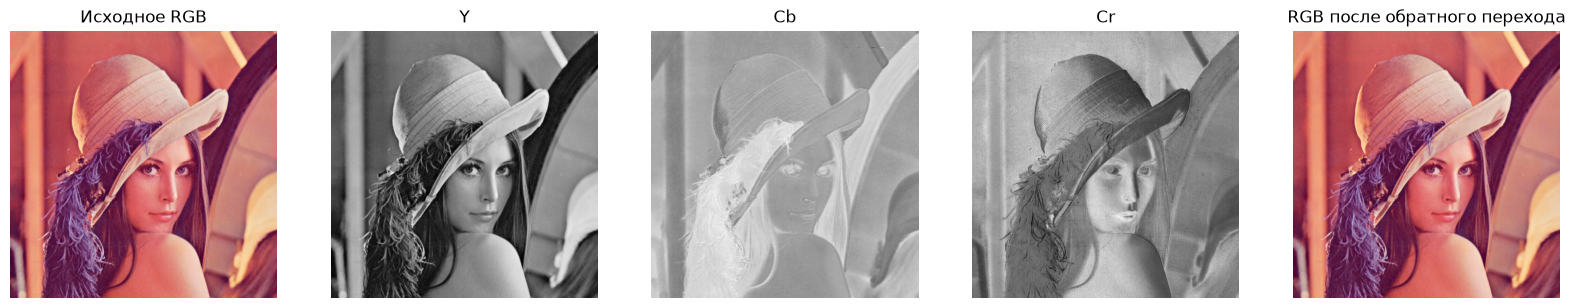

Тип: 3 | цветовое пространство: YCbCr
Данные совпадают: True


In [3]:
# ==================================================
# RGB <-> YCbCr
# ==================================================

def rgb_to_ycbcr(img):
    """img: массив HxWx3 (uint8). Возвращает массив float64 HxWx3 (Y, Cb, Cr)."""

    img = img.astype(np.float64)

    R = img[..., 0]
    G = img[..., 1]
    B = img[..., 2]

    Y = 0.299 * R + 0.587 * G + 0.114 * B
    Cb = -0.168736 * R - 0.331264 * G + 0.5 * B + 128
    Cr = 0.5 * R - 0.418688 * G - 0.081312 * B + 128

    return np.stack((Y, Cb, Cr), axis=-1)


def ycbcr_to_rgb(img):
    """img: массив HxWx3 (Y, Cb, Cr). Возвращает массив uint8 HxWx3."""

    img = img.astype(np.float64)

    Y = img[..., 0]
    Cb = img[..., 1] - 128
    Cr = img[..., 2] - 128

    R = Y + 1.402 * Cr
    G = Y - 0.344136 * Cb - 0.714136 * Cr
    B = Y + 1.772 * Cb

    return to_uint8(np.stack((R, G, B), axis=-1))


def to_uint8(array):
    return np.clip(np.rint(array), 0, 255).astype(np.uint8)


# ==================================================
# ПРОВЕРКА
# ==================================================

lena_array, _ = load_image(TEST_FILES["lena"])

ycbcr = rgb_to_ycbcr(lena_array)

# без округления в промежуточном виде
restored_float = ycbcr_to_rgb(ycbcr)

# с хранением YCbCr в байтах (как в raw файле)
ycbcr_bytes = to_uint8(ycbcr)
restored_bytes = ycbcr_to_rgb(ycbcr_bytes)

print(
    "Максимальная ошибка, YCbCr во float :",
    np.abs(restored_float.astype(int) - lena_array).max()
)

print(
    "Максимальная ошибка, YCbCr в uint8  :",
    np.abs(restored_bytes.astype(int) - lena_array).max()
)

diff = np.abs(restored_bytes.astype(int) - lena_array)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(lena_array)
axes[0].set_title("Исходное RGB")

axes[1].imshow(ycbcr_bytes[..., 0], cmap="gray")
axes[1].set_title("Y")

axes[2].imshow(ycbcr_bytes[..., 1], cmap="gray")
axes[2].set_title("Cb")

axes[3].imshow(ycbcr_bytes[..., 2], cmap="gray")
axes[3].set_title("Cr")

axes[4].imshow(restored_bytes)
axes[4].set_title("RGB после обратного перехода")

for ax in axes:
    ax.axis("off")

plt.show()

# ==================================================
# YCbCr В RAW ФАЙЛЕ (метаданные о цветовом пространстве)
# ==================================================

save_custom_raw(ycbcr_bytes, os.path.join(TEST_DIR, "lena_ycbcr.raw"), RAW_COLOR, CS_YCBCR)

loaded, loaded_type, loaded_cs = load_custom_raw(os.path.join(TEST_DIR, "lena_ycbcr.raw"))

print("Тип:", loaded_type, "| цветовое пространство:", "YCbCr" if loaded_cs == CS_YCBCR else "RGB")
print("Данные совпадают:", np.array_equal(loaded, ycbcr_bytes))

#### 3. Downsampling / Upsampling / Resizing

k = 1   размер после децимации: (512, 512), PSNR: inf дБ
k = 2   размер после децимации: (256, 256), PSNR: 25.65 дБ
k = 4   размер после децимации: (128, 128), PSNR: 19.62 дБ
k = 8   размер после децимации: (64, 64), PSNR: 16.16 дБ
k = 16  размер после децимации: (32, 32), PSNR: 13.72 дБ


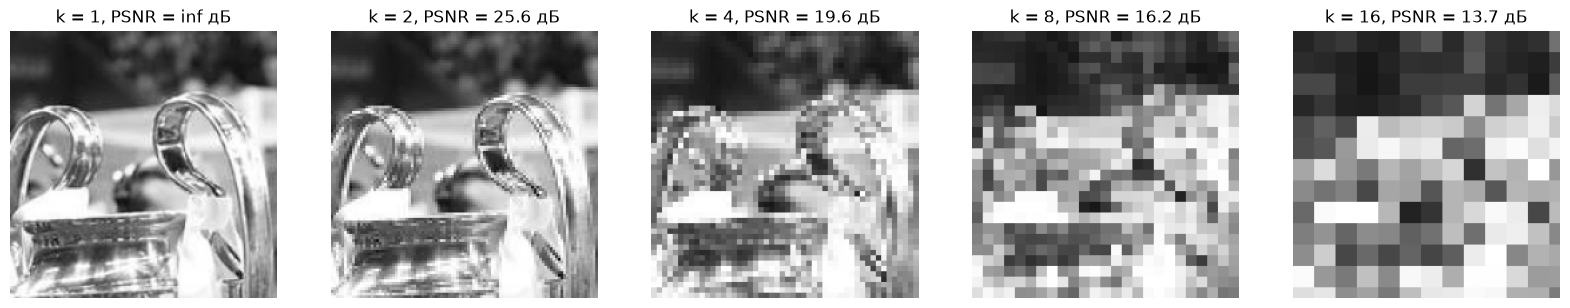

In [4]:
# ==================================================
# ДЕЦИМАЦИЯ И АПСЕМПЛИНГ
# ==================================================

def downsample(channel, k=2):
    """Децимация с коэффициентом k: остаётся каждый k-й пиксель по каждой оси."""

    return channel[::k, ::k]


def upsample(channel, k=2, shape=None):
    """Апсемплинг: каждый пиксель повторяется в блоке kxk."""

    result = np.repeat(np.repeat(channel, k, axis=0), k, axis=1)

    if shape is not None:
        result = result[:shape[0], :shape[1]]

    return result


# ==================================================
# ПРОВЕРКА: ПИКСЕЛИЗАЦИЯ ПРИ РОСТЕ КОЭФФИЦИЕНТА
# ==================================================

def mse(a, b):
    return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)


def psnr(a, b):

    error = mse(a, b)

    if error == 0:
        return float("inf")

    return 10 * math.log10(255 ** 2 / error)


gray_array, _ = load_image(TEST_FILES["gray"])

factors = [1, 2, 4, 8, 16]

fig, axes = plt.subplots(1, len(factors), figsize=(20, 4.5))

for ax, k in zip(axes, factors):

    small = downsample(gray_array, k)
    big = upsample(small, k, gray_array.shape)

    ax.imshow(big[:200, :200], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}, PSNR = {psnr(gray_array, big):.1f} дБ")
    ax.axis("off")

    print(f"k = {k:<3} размер после децимации: {small.shape}, PSNR: {psnr(gray_array, big):.2f} дБ")

plt.show()

In [5]:
# ==================================================
# ЛИНЕЙНАЯ ИНТЕРПОЛЯЦИЯ, ЛИНЕЙНЫЙ СПЛАЙН, БИЛИНЕЙНАЯ
# ==================================================

def linear_interp(x1, x2, y1, y2, x):
    """Значение прямой через (x1, y1) и (x2, y2) в точке x."""

    if x1 == x2:
        return y1

    t = (x - x1) / (x2 - x1)

    return y1 * (1 - t) + y2 * t


def linear_spline(xs, ys, x):
    """Линейный сплайн по узлам xs (по возрастанию), значениям ys, в точке x."""

    i = bisect.bisect_right(xs, x) - 1

    i = min(max(i, 0), len(xs) - 2)

    return linear_interp(xs[i], xs[i + 1], ys[i], ys[i + 1], x)


def bilinear_interp(x1, x2, y1, y2, z11, z12, z21, z22, x, y):
    """
    z11 = z(x1, y1), z12 = z(x1, y2), z21 = z(x2, y1), z22 = z(x2, y2)
    """

    # сначала по x на двух горизонталях
    z_low = linear_interp(x1, x2, z11, z21, x)
    z_high = linear_interp(x1, x2, z12, z22, x)

    # затем по y
    return linear_interp(y1, y2, z_low, z_high, y)


# ==================================================
# ПРОВЕРКА
# ==================================================

print("linear_interp(0, 10, 0, 100, 2.5)       =", linear_interp(0, 10, 0, 100, 2.5))

xs = [0, 1, 3, 6]
ys = [0, 2, 1, 4]

print("linear_spline в точках 0.5, 2, 4.5      =",
      [linear_spline(xs, ys, x) for x in (0.5, 2, 4.5)])

print("bilinear_interp в центре квадрата       =",
      bilinear_interp(0, 1, 0, 1, 0, 10, 20, 30, 0.5, 0.5))

linear_interp(0, 10, 0, 100, 2.5)       = 25.0
linear_spline в точках 0.5, 2, 4.5      = [1.0, 1.5, 2.5]
bilinear_interp в центре квадрата       = 15.0


## __Задание 2__
#### 1. Downsampling/Upsampling/Resizing

128x128 -> 64x64: (64, 64), 0.03 с
128x128 -> 128x128: (128, 128), 0.11 с
128x128 -> 200x300: (200, 300), 0.49 с
128x128 -> 256x256: (256, 256), 0.59 с


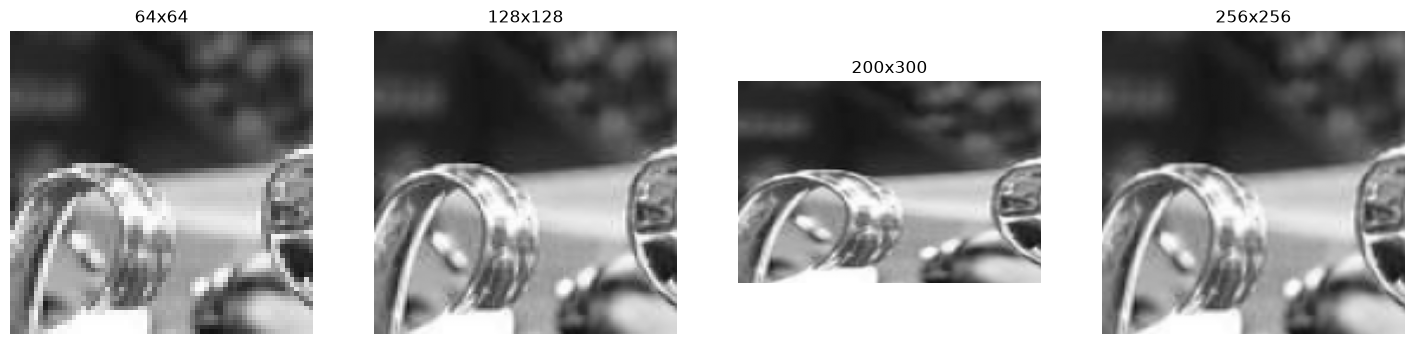

Тот же размер, максимальное отличие: 0


In [6]:
# ==================================================
# ИЗМЕНЕНИЕ РАЗМЕРА ИЗОБРАЖЕНИЯ БИЛИНЕЙНОЙ ИНТЕРПОЛЯЦИЕЙ
# ==================================================

def resize_bilinear(img, new_height, new_width):
    """
    Узлы интерполяции - пиксели исходного изображения.
    Для каждого пикселя результата вычисляется его координата в исходном
    изображении и значение берётся из билинейной интерполяции по четырём
    ближайшим узлам.
    """

    if img.ndim == 3:

        channels = [
            resize_bilinear(img[..., c], new_height, new_width)
            for c in range(img.shape[2])
        ]

        return np.stack(channels, axis=-1)

    height, width = img.shape

    result = np.zeros((new_height, new_width))

    # координаты по осям считаем один раз
    y_src = [
        y * (height - 1) / (new_height - 1) if new_height > 1 else 0
        for y in range(new_height)
    ]

    x_src = [
        x * (width - 1) / (new_width - 1) if new_width > 1 else 0
        for x in range(new_width)
    ]

    for yy, y in enumerate(y_src):

        y1 = int(math.floor(y))
        y2 = min(y1 + 1, height - 1)

        for xx, x in enumerate(x_src):

            x1 = int(math.floor(x))
            x2 = min(x1 + 1, width - 1)

            result[yy, xx] = bilinear_interp(
                x1, x2, y1, y2,
                img[y1, x1], img[y2, x1],
                img[y1, x2], img[y2, x2],
                x, y
            )

    if img.dtype == np.uint8:
        return to_uint8(result)

    return result


# ==================================================
# ПРОВЕРКА
# ==================================================

small_gray = gray_array[:128, :128]

test_sizes = [(64, 64), (128, 128), (200, 300), (256, 256)]

fig, axes = plt.subplots(1, len(test_sizes), figsize=(18, 4.5))

for ax, (h, w) in zip(axes, test_sizes):

    t = time.time()
    resized = resize_bilinear(small_gray, h, w)

    ax.imshow(resized, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{h}x{w}")
    ax.axis("off")

    print(f"128x128 -> {h}x{w}: {resized.shape}, {time.time() - t:.2f} с")

plt.show()

# при том же размере изображение не должно меняться
same = resize_bilinear(small_gray, 128, 128)
print("Тот же размер, максимальное отличие:", np.abs(same.astype(int) - small_gray).max())

#### 2. Дискретное косинусное преобразование

In [7]:
# ==================================================
# РАЗБИЕНИЕ НА БЛОКИ
# ==================================================

BLOCK_SIZE = 8


def split_into_blocks(channel, N=BLOCK_SIZE, M=None):
    """
    Разбиение канала на блоки NxM (по умолчанию 8x8).
    Неполные блоки справа и снизу дополняются средним значением
    имеющихся в блоке пикселей.
    Возвращает массив блоков (nb, N, M) и размер сетки блоков (по y, по x).
    """

    if M is None:
        M = N

    channel = channel.astype(np.float64)

    height, width = channel.shape

    blocks_y = -(-height // N)
    blocks_x = -(-width // M)

    padded = np.zeros((blocks_y * N, blocks_x * M))
    padded[:height, :width] = channel

    # неполные блоки: правый столбец блоков и нижняя строка блоков
    edge = set()

    if width % M:
        edge.update((by, blocks_x - 1) for by in range(blocks_y))

    if height % N:
        edge.update((blocks_y - 1, bx) for bx in range(blocks_x))

    for by, bx in edge:

        y0, x0 = by * N, bx * M

        valid_h = min(N, height - y0)
        valid_w = min(M, width - x0)

        mean = channel[y0:y0 + valid_h, x0:x0 + valid_w].mean()

        padded[y0:y0 + N, x0:x0 + M] = mean
        padded[y0:y0 + valid_h, x0:x0 + valid_w] = channel[y0:y0 + valid_h, x0:x0 + valid_w]

    blocks = (
        padded
        .reshape(blocks_y, N, blocks_x, M)
        .swapaxes(1, 2)
        .reshape(-1, N, M)
    )

    return blocks, (blocks_y, blocks_x)


def merge_blocks(blocks, grid, shape):
    """Обратная операция: собирает блоки в канал и обрезает до исходного размера."""

    blocks_y, blocks_x = grid
    N, M = blocks.shape[1:]

    padded = (
        blocks
        .reshape(blocks_y, blocks_x, N, M)
        .swapaxes(1, 2)
        .reshape(blocks_y * N, blocks_x * M)
    )

    return padded[:shape[0], :shape[1]]


# ==================================================
# ПРОВЕРКА
# ==================================================

test_channel = np.arange(13 * 21, dtype=np.float64).reshape(13, 21)

test_blocks, test_grid = split_into_blocks(test_channel, 8)

print("Изображение 13x21 -> сетка блоков:", test_grid, "блоков:", len(test_blocks))
print("Последний блок (дополнен средним), первая строка:", test_blocks[-1][0])
print("Склейка возвращает исходный канал:",
      np.array_equal(merge_blocks(test_blocks, test_grid, test_channel.shape), test_channel))

Изображение 13x21 -> сетка блоков: (2, 3) блоков: 6
Последний блок (дополнен средним), первая строка: [184. 185. 186. 187. 188. 228. 228. 228.]
Склейка возвращает исходный канал: True


In [8]:
# ==================================================
# ДКП "В ЛОБ" ДЛЯ БЛОКА NxM
# ==================================================

def dct2_naive(block):
    """
    Прямое ДКП-2 блока произвольного размера N x M по определению.
    S[v, u] = c(u) c(v) sum_y sum_x s[y, x] cos((2x+1)u pi / 2M) cos((2y+1)v pi / 2N)
    """

    N, M = block.shape

    S = np.zeros((N, M))

    for v in range(N):

        for u in range(M):

            total = 0.0

            for y in range(N):

                for x in range(M):

                    total += (
                        block[y, x]
                        * math.cos((2 * x + 1) * u * math.pi / (2 * M))
                        * math.cos((2 * y + 1) * v * math.pi / (2 * N))
                    )

            cu = math.sqrt(1 / M) if u == 0 else math.sqrt(2 / M)
            cv = math.sqrt(1 / N) if v == 0 else math.sqrt(2 / N)

            S[v, u] = cu * cv * total

    return S


def idct2_naive(S):
    """Обратное ДКП-2 блока N x M по определению."""

    N, M = S.shape

    block = np.zeros((N, M))

    for y in range(N):

        for x in range(M):

            total = 0.0

            for v in range(N):

                for u in range(M):

                    cu = math.sqrt(1 / M) if u == 0 else math.sqrt(2 / M)
                    cv = math.sqrt(1 / N) if v == 0 else math.sqrt(2 / N)

                    total += (
                        cu * cv * S[v, u]
                        * math.cos((2 * x + 1) * u * math.pi / (2 * M))
                        * math.cos((2 * y + 1) * v * math.pi / (2 * N))
                    )

            block[y, x] = total

    return block


# ==================================================
# ПРОВЕРКА
# ==================================================

rng = np.random.default_rng(1)

block8 = rng.integers(0, 256, (8, 8)).astype(np.float64) - 128
block_rect = rng.integers(0, 256, (5, 9)).astype(np.float64) - 128

for name, b in (("8x8", block8), ("5x9", block_rect)):

    S = dct2_naive(b)
    back = idct2_naive(S)

    print(f"{name}: максимальная ошибка прямое+обратное ДКП = {np.abs(back - b).max():.2e}")

# ==================================================
# ВРЕМЕННАЯ СЛОЖНОСТЬ
# ==================================================

print("\nВремя ДКП одного блока NxN:")

for N in (4, 8, 16, 32):

    b = rng.random((N, N))

    t = time.time()
    dct2_naive(b)

    print(f"N = {N:<3} {time.time() - t:.4f} с")

print("\nВ каждом из N*N коэффициентов суммируется N*N слагаемых: O(N^2 * M^2), для квадратного блока O(N^4).")
print("Значения коэффициентов дробные, поэтому хранятся во float (float64; после квантования - целые, хватает int16).")

8x8: максимальная ошибка прямое+обратное ДКП = 1.71e-13
5x9: максимальная ошибка прямое+обратное ДКП = 1.85e-13

Время ДКП одного блока NxN:
N = 4   0.0000 с
N = 8   0.0042 с
N = 16  0.0337 с
N = 32  0.6805 с

В каждом из N*N коэффициентов суммируется N*N слагаемых: O(N^2 * M^2), для квадратного блока O(N^4).
Значения коэффициентов дробные, поэтому хранятся во float (float64; после квантования - целые, хватает int16).


In [9]:
# ==================================================
# ДКП ЧЕРЕЗ ПЕРЕМНОЖЕНИЕ МАТРИЦ
# S = C^T s C,   s = C S C^T
# ==================================================

def dct_matrix(N):
    """C[i, j] = c_j * cos((2i+1) j pi / 2N), c_0 = sqrt(1/N), c_j = sqrt(2/N)."""

    C = np.zeros((N, N))

    for i in range(N):

        for j in range(N):

            cj = math.sqrt(1 / N) if j == 0 else math.sqrt(2 / N)

            C[i, j] = cj * math.cos((2 * i + 1) * j * math.pi / (2 * N))

    return C


def dct2_matrix(block):
    """Прямое ДКП-2 блока (или стопки блоков) через матрицы. Размер блока N x M любой."""

    N, M = block.shape[-2:]

    return dct_matrix(N).T @ block @ dct_matrix(M)


def idct2_matrix(S):
    """Обратное ДКП-2 через матрицы."""

    N, M = S.shape[-2:]

    return dct_matrix(N) @ S @ dct_matrix(M).T


# ==================================================
# ПРОВЕРКА
# ==================================================

for name, b in (("8x8", block8), ("5x9", block_rect)):

    S_naive = dct2_naive(b)
    S_matrix = dct2_matrix(b)

    print(
        f"{name}: матричное и по определению отличаются не более чем на "
        f"{np.abs(S_naive - S_matrix).max():.2e}, "
        f"прямое+обратное: {np.abs(idct2_matrix(S_matrix) - b).max():.2e}"
    )

N = 8
C8 = dct_matrix(N)

print("C^T C = единичная матрица:", np.allclose(C8.T @ C8, np.eye(N)))

# сравнение скорости
b = rng.random((16, 16))

t = time.time()
for _ in range(20):
    dct2_naive(b)
t_naive = (time.time() - t) / 20

t = time.time()
for _ in range(20):
    dct2_matrix(b)
t_matrix = (time.time() - t) / 20

print(f"\nБлок 16x16: по определению {t_naive:.5f} с, через матрицы {t_matrix:.6f} с")
print("Через матрицы: O(N^3) вместо O(N^4) на блок.")

8x8: матричное и по определению отличаются не более чем на 5.68e-14, прямое+обратное: 1.71e-13
5x9: матричное и по определению отличаются не более чем на 6.39e-14, прямое+обратное: 1.56e-13
C^T C = единичная матрица: True

Блок 16x16: по определению 0.04152 с, через матрицы 0.000328 с
Через матрицы: O(N^3) вместо O(N^4) на блок.


In [10]:
# ==================================================
# ПРОВЕРКА НА ИЗОБРАЖЕНИИ: ДКП -> ОБРАТНОЕ ДКП
# ==================================================

blocks, grid = split_into_blocks(gray_array, 8)

dct_blocks = dct2_matrix(blocks - 128)

restored_blocks = idct2_matrix(dct_blocks) + 128

restored = merge_blocks(restored_blocks, grid, gray_array.shape)

print("Максимальное отличие после ДКП и обратного ДКП:", np.abs(restored - gray_array).max())
print("После округления изображение совпадает:", np.array_equal(to_uint8(restored), gray_array))

# ==================================================
# КВАНТОВАНИЕ И НОРМАЛИЗАЦИЯ
# ==================================================

Q_LUMA = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99],
])

Q_CHROMA = np.array([
    [17, 18, 24, 47, 99, 99, 99, 99],
    [18, 21, 26, 66, 99, 99, 99, 99],
    [24, 26, 56, 99, 99, 99, 99, 99],
    [47, 66, 99, 99, 99, 99, 99, 99],
    [99, 99, 99, 99, 99, 99, 99, 99],
    [99, 99, 99, 99, 99, 99, 99, 99],
    [99, 99, 99, 99, 99, 99, 99, 99],
    [99, 99, 99, 99, 99, 99, 99, 99],
])


def quantize(S, Q):
    """c' = round(c / q)"""

    return np.rint(S / Q).astype(np.int32)


def dequantize(Sq, Q):
    """c = c' * q"""

    return Sq * Q


q_blocks = quantize(dct_blocks, Q_LUMA)

restored_q = merge_blocks(idct2_matrix(dequantize(q_blocks, Q_LUMA)) + 128, grid, gray_array.shape)

print("\nПосле квантования с таблицей яркости:")
print("ненулевых коэффициентов было:", np.count_nonzero(np.abs(dct_blocks) > 0.5), "стало:", np.count_nonzero(q_blocks))
print(f"PSNR после квантования и нормализации: {psnr(gray_array, to_uint8(restored_q)):.2f} дБ")

Максимальное отличие после ДКП и обратного ДКП: 2.8421709430404007e-13
После округления изображение совпадает: True

После квантования с таблицей яркости:
ненулевых коэффициентов было: 163880 стало: 35857
PSNR после квантования и нормализации: 35.93 дБ


#### 3. Зигзаг-обход

In [11]:
# ==================================================
# ЗИГЗАГ ОБХОД МАТРИЦЫ NxM
# ==================================================

def zigzag_indices(rows, cols):
    """Список позиций (i, j) в порядке зигзага для матрицы rows x cols."""

    order = []

    for s in range(rows + cols - 1):

        diagonal = list(range(max(0, s - cols + 1), min(s, rows - 1) + 1))

        # чётные диагонали идут снизу вверх, нечётные - сверху вниз
        if s % 2 == 0:
            diagonal.reverse()

        for i in diagonal:
            order.append((i, s - i))

    return order


def zigzag(matrix):
    """Значения матрицы в порядке зигзага."""

    rows, cols = matrix.shape

    return [matrix[i, j].item() for i, j in zigzag_indices(rows, cols)]


def inverse_zigzag(values, rows, cols):
    """Обратная операция: список значений -> матрица rows x cols."""

    matrix = np.zeros((rows, cols), dtype=np.asarray(values).dtype)

    for value, (i, j) in zip(values, zigzag_indices(rows, cols)):
        matrix[i, j] = value

    return matrix


# ==================================================
# ПРОВЕРКА
# ==================================================

m4 = np.arange(16).reshape(4, 4)

print("Матрица 4x4:")
print(m4)
print("Зигзаг:", zigzag(m4))

m35 = np.arange(15).reshape(3, 5)

print("\nМатрица 3x5:")
print(m35)
print("Зигзаг:", zigzag(m35))

print("\nОбратный зигзаг возвращает матрицу:",
      np.array_equal(inverse_zigzag(zigzag(m35), 3, 5), m35),
      np.array_equal(inverse_zigzag(zigzag(Q_LUMA), 8, 8), Q_LUMA))

# для блоков 8x8 порядок считаем один раз
ZIGZAG_8 = np.array([i * 8 + j for i, j in zigzag_indices(8, 8)])

Матрица 4x4:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]
Зигзаг: [0, 1, 4, 8, 5, 2, 3, 6, 9, 12, 13, 10, 7, 11, 14, 15]

Матрица 3x5:
[[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]]
Зигзаг: [0, 1, 5, 10, 6, 2, 3, 7, 11, 12, 8, 4, 9, 13, 14]

Обратный зигзаг возвращает матрицу: True True


#### 4. Разностное кодирование и RLE

In [12]:
# ==================================================
# РАЗНОСТНОЕ КОДИРОВАНИЕ DC
# ==================================================

def dc_diff_encode(dc_list):

    result = []
    previous = 0

    for dc in dc_list:

        result.append(dc - previous)

        previous = dc

    return result


def dc_diff_decode(diff_list):

    result = []
    current = 0

    for diff in diff_list:

        current += diff

        result.append(current)

    return result


# ==================================================
# RLE ДЛЯ AC КОЭФФИЦИЕНТОВ БЛОКА (ITU-T T.81)
# пара (количество нулей, следующий элемент)
# (15, 0) - ZRL, 16 нулей подряд
# (0, 0)  - EOB, дальше в блоке только нули
# ==================================================

def rle_encode_ac(ac):
    """ac: список из 63 AC коэффициентов."""

    last = -1

    for i, value in enumerate(ac):
        if value != 0:
            last = i

    codes = []
    zeros = 0

    for value in ac[:last + 1]:

        if value == 0:
            zeros += 1
            continue

        while zeros > 15:
            codes.append((15, 0))
            zeros -= 16

        codes.append((zeros, value))
        zeros = 0

    if last < len(ac) - 1:
        codes.append((0, 0))

    return codes


def rle_decode_ac(codes, length=63):

    ac = []

    for zeros, value in codes:

        if (zeros, value) == (0, 0):
            break

        if (zeros, value) == (15, 0):
            ac.extend([0] * 16)
            continue

        ac.extend([0] * zeros)
        ac.append(value)

    ac.extend([0] * (length - len(ac)))

    return ac


# ==================================================
# ПРОВЕРКА
# ==================================================

dc = [10, 12, 9, 9, 15]

diffs = dc_diff_encode(dc)

print("DC:", dc)
print("Разности:", diffs)
print("Восстановлено:", dc_diff_decode(diffs))

ac = [5, 0, 0, 3] + [0] * 20 + [-2] + [0] * 38

print("\nAC:", ac[:30], "...")
print("RLE:", rle_encode_ac(ac))
print("Декодирование совпадает:", rle_decode_ac(rle_encode_ac(ac)) == ac)

ac_last = [0] * 62 + [7]

print("\nПоследний коэффициент ненулевой:", rle_encode_ac(ac_last))
print("Декодирование совпадает:", rle_decode_ac(rle_encode_ac(ac_last)) == ac_last)

print("Только нули:", rle_encode_ac([0] * 63))

DC: [10, 12, 9, 9, 15]
Разности: [10, 2, -3, 0, 6]
Восстановлено: [10, 12, 9, 9, 15]

AC: [5, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -2, 0, 0, 0, 0, 0] ...
RLE: [(0, 5), (2, 3), (15, 0), (4, -2), (0, 0)]
Декодирование совпадает: True

Последний коэффициент ненулевой: [(15, 0), (15, 0), (15, 0), (14, 7)]
Декодирование совпадает: True
Только нули: [(0, 0)]


#### 5. Кодирование переменной длины

In [13]:
# ==================================================
# КОДИРОВАНИЕ ПЕРЕМЕННОЙ ДЛИНЫ (ITU-T T.81)
# значение -> (размер в битах, биты амплитуды)
# отрицательные числа: биты прямого кода значения вычитаются из 2^size - 1
# ==================================================

def vlc_size(value):

    return abs(int(value)).bit_length()


def vlc_encode(value):
    """Возвращает (size, bits). Для нуля size = 0 и биты пустые."""

    value = int(value)

    size = vlc_size(value)

    if size == 0:
        return 0, ""

    if value < 0:
        value += (1 << size) - 1

    return size, format(value, f"0{size}b")


def vlc_decode(size, bits):

    if size == 0:
        return 0

    value = int(bits, 2)

    if bits[0] == "0":
        value -= (1 << size) - 1

    return value


def vlc_rle_encode_ac(ac):
    """RLE + кодирование переменной длины: список троек (zeros, size, bits)."""

    result = []

    for zeros, value in rle_encode_ac(ac):

        size, bits = vlc_encode(value)

        result.append((zeros, size, bits))

    return result


# ==================================================
# ПРОВЕРКА
# ==================================================

for value in (0, 1, -1, 5, -5, 255, -255, 1023, -1024):

    size, bits = vlc_encode(value)

    print(f"{value:>6} -> size = {size:<2} bits = {bits:<12} обратно: {vlc_decode(size, bits)}")

assert all(vlc_decode(*vlc_encode(v)) == v for v in range(-2047, 2048))

print("\nДля всех значений от -2047 до 2047 кодирование и декодирование согласованы")

print("\nRLE+VLC:", vlc_rle_encode_ac([5, 0, 0, 3] + [0] * 20 + [-2] + [0] * 38))

     0 -> size = 0  bits =              обратно: 0
     1 -> size = 1  bits = 1            обратно: 1
    -1 -> size = 1  bits = 0            обратно: -1
     5 -> size = 3  bits = 101          обратно: 5
    -5 -> size = 3  bits = 010          обратно: -5
   255 -> size = 8  bits = 11111111     обратно: 255
  -255 -> size = 8  bits = 00000000     обратно: -255
  1023 -> size = 10 bits = 1111111111   обратно: 1023
 -1024 -> size = 11 bits = 01111111111  обратно: -1024

Для всех значений от -2047 до 2047 кодирование и декодирование согласованы

RLE+VLC: [(0, 3, '101'), (2, 2, '11'), (15, 0, ''), (4, 2, '01'), (0, 0, '')]


#### 6. Кодирование алгоритмом Хаффмана

In [14]:
# ==================================================
# ТАБЛИЦЫ ХАФФМАНА СТАНДАРТА ITU-T T.81 (приложение K.3)
# задаются как в файле JPEG: BITS - сколько кодов каждой длины от 1 до 16,
# VALS - символы в порядке возрастания длины кода
# DC: символ - размер разности (0..11)
# AC: символ = (количество нулей << 4) | размер
# ==================================================

HUFF_DC_LUMA_BITS = [0, 1, 5, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0]
HUFF_DC_LUMA_VALS = [
    0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11
]

HUFF_AC_LUMA_BITS = [0, 2, 1, 3, 3, 2, 4, 3, 5, 5, 4, 4, 0, 0, 1, 125]
HUFF_AC_LUMA_VALS = [
    1, 2, 3, 0, 4, 17, 5, 18, 33, 49, 65, 6, 19, 81, 97, 7,
    34, 113, 20, 50, 129, 145, 161, 8, 35, 66, 177, 193, 21, 82, 209, 240,
    36, 51, 98, 114, 130, 9, 10, 22, 23, 24, 25, 26, 37, 38, 39, 40,
    41, 42, 52, 53, 54, 55, 56, 57, 58, 67, 68, 69, 70, 71, 72, 73,
    74, 83, 84, 85, 86, 87, 88, 89, 90, 99, 100, 101, 102, 103, 104, 105,
    106, 115, 116, 117, 118, 119, 120, 121, 122, 131, 132, 133, 134, 135, 136, 137,
    138, 146, 147, 148, 149, 150, 151, 152, 153, 154, 162, 163, 164, 165, 166, 167,
    168, 169, 170, 178, 179, 180, 181, 182, 183, 184, 185, 186, 194, 195, 196, 197,
    198, 199, 200, 201, 202, 210, 211, 212, 213, 214, 215, 216, 217, 218, 225, 226,
    227, 228, 229, 230, 231, 232, 233, 234, 241, 242, 243, 244, 245, 246, 247, 248,
    249, 250
]

HUFF_DC_CHROMA_BITS = [0, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
HUFF_DC_CHROMA_VALS = [
    0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11
]

HUFF_AC_CHROMA_BITS = [0, 2, 1, 2, 4, 4, 3, 4, 7, 5, 4, 4, 0, 1, 2, 119]
HUFF_AC_CHROMA_VALS = [
    0, 1, 2, 3, 17, 4, 5, 33, 49, 6, 18, 65, 81, 7, 97, 113,
    19, 34, 50, 129, 8, 20, 66, 145, 161, 177, 193, 9, 35, 51, 82, 240,
    21, 98, 114, 209, 10, 22, 36, 52, 225, 37, 241, 23, 24, 25, 26, 38,
    39, 40, 41, 42, 53, 54, 55, 56, 57, 58, 67, 68, 69, 70, 71, 72,
    73, 74, 83, 84, 85, 86, 87, 88, 89, 90, 99, 100, 101, 102, 103, 104,
    105, 106, 115, 116, 117, 118, 119, 120, 121, 122, 130, 131, 132, 133, 134, 135,
    136, 137, 138, 146, 147, 148, 149, 150, 151, 152, 153, 154, 162, 163, 164, 165,
    166, 167, 168, 169, 170, 178, 179, 180, 181, 182, 183, 184, 185, 186, 194, 195,
    196, 197, 198, 199, 200, 201, 202, 210, 211, 212, 213, 214, 215, 216, 217, 218,
    226, 227, 228, 229, 230, 231, 232, 233, 234, 242, 243, 244, 245, 246, 247, 248,
    249, 250
]

In [15]:
def build_huffman_codes(bits, vals):
    """Строит коды по BITS и VALS (приложение C стандарта). Возвращает {символ: строка из 0 и 1}."""

    codes = {}

    code_value = 0
    k = 0

    for length in range(1, 17):

        for _ in range(bits[length - 1]):

            codes[vals[k]] = format(code_value, f"0{length}b")

            code_value += 1
            k += 1

        code_value <<= 1

    return codes


def build_decode_table(codes):
    """Таблица для декодирования: по следующим 16 битам сразу находится (символ, длина кода)."""

    table = [None] * 65536

    for symbol, code in codes.items():

        length = len(code)
        start = int(code, 2) << (16 - length)

        for i in range(start, start + (1 << (16 - length))):
            table[i] = (symbol, length)

    return table


DC_CODES = {
    "luma": build_huffman_codes(HUFF_DC_LUMA_BITS, HUFF_DC_LUMA_VALS),
    "chroma": build_huffman_codes(HUFF_DC_CHROMA_BITS, HUFF_DC_CHROMA_VALS),
}

AC_CODES = {
    "luma": build_huffman_codes(HUFF_AC_LUMA_BITS, HUFF_AC_LUMA_VALS),
    "chroma": build_huffman_codes(HUFF_AC_CHROMA_BITS, HUFF_AC_CHROMA_VALS),
}


def huffman_encode_dc(size, bits, dc_codes):
    """Код размера DC разности по таблице + биты амплитуды."""

    return dc_codes[size] + bits


def huffman_encode_ac(zeros, size, bits, ac_codes):
    """Код пары (zeros, size) по таблице + биты амплитуды."""

    return ac_codes[(zeros << 4) | size] + bits


# ==================================================
# ПРОВЕРКА
# ==================================================

print("DC (яркость): размер 0 ->", DC_CODES["luma"][0], "| размер 2 ->", DC_CODES["luma"][2], "| размер 11 ->", DC_CODES["luma"][11])
print("AC (яркость): EOB (0,0) ->", AC_CODES["luma"][0x00], "| ZRL (15,0) ->", AC_CODES["luma"][0xF0], "| (0,1) ->", AC_CODES["luma"][0x01])
print("Кодов в таблицах DC / AC:", len(DC_CODES["luma"]), "/", len(AC_CODES["luma"]))

# код должен быть префиксным: ни один не является началом другого
all_codes = sorted(AC_CODES["luma"].values())
print("Префиксность AC таблицы:", all(not b.startswith(a) for a, b in zip(all_codes, all_codes[1:])))

print("\nПример: DC разность 5 ->", huffman_encode_dc(*vlc_encode(5), DC_CODES["luma"]))
print("Пример: AC (2, -3) ->", huffman_encode_ac(2, *vlc_encode(-3), AC_CODES["luma"]))

DC (яркость): размер 0 -> 00 | размер 2 -> 011 | размер 11 -> 111111110
AC (яркость): EOB (0,0) -> 1010 | ZRL (15,0) -> 11111111001 | (0,1) -> 00
Кодов в таблицах DC / AC: 12 / 162
Префиксность AC таблицы: True

Пример: DC разность 5 -> 100101
Пример: AC (2, -3) -> 1111100100


#### 7. Изменение качества изображения при сжатии

In [16]:
# ==================================================
# ТАБЛИЦА КВАНТОВАНИЯ ДЛЯ ЗАДАННОГО КАЧЕСТВА
# S = 5000 / Quality               при Quality < 50
# S = 200 - 2 * Quality            при Quality >= 50
# q' = ceil(q * S / 100)
# ==================================================

def adapt_quant_table(table, quality):

    quality = min(max(int(quality), 1), 100)

    if quality < 50:
        scale = 5000 / quality
    else:
        scale = 200 - 2 * quality

    adapted = np.ceil(table * scale / 100)

    # значения должны помещаться в байт, а ноль недопустим
    return np.clip(adapted, 1, 255).astype(np.int32)


# ==================================================
# ПРОВЕРКА
# ==================================================

for quality in (10, 50, 90):

    print(f"Quality = {quality}, левый верхний угол таблицы яркости:")
    print(adapt_quant_table(Q_LUMA, quality)[:3, :4])
    print()

print("При Quality = 50 таблица совпадает с базовой:", np.array_equal(adapt_quant_table(Q_LUMA, 50), Q_LUMA))

Quality = 10, левый верхний угол таблицы яркости:
[[ 80  55  50  80]
 [ 60  60  70  95]
 [ 70  65  80 120]]

Quality = 50, левый верхний угол таблицы яркости:
[[16 11 10 16]
 [12 12 14 19]
 [14 13 16 24]]

Quality = 90, левый верхний угол таблицы яркости:
[[4 3 2 4]
 [3 3 3 4]
 [3 3 4 5]]

При Quality = 50 таблица совпадает с базовой: True


#### 8. Запись в файл и чтение

In [17]:
# ==================================================
# ЭНТРОПИЙНОЕ КОДИРОВАНИЕ КАНАЛА
# для каждого блока: DC разность (VLC + Хаффман), затем AC (RLE + VLC + Хаффман)
# ==================================================

def bits_to_bytes(bits):

    bits += "0" * (-len(bits) % 8)

    if not bits:
        return b""

    return int(bits, 2).to_bytes(len(bits) // 8, "big")


def bytes_to_bits(data):

    if not data:
        return ""

    return bin(int.from_bytes(data, "big"))[2:].zfill(8 * len(data))


def entropy_encode(q_blocks, dc_codes, ac_codes):
    """q_blocks: квантованные коэффициенты (nb, 8, 8). Возвращает байты."""

    flat = q_blocks.reshape(len(q_blocks), 64)[:, ZIGZAG_8]

    dc_diffs = dc_diff_encode(flat[:, 0].tolist())

    pieces = []

    for k in range(len(flat)):

        size, bits = vlc_encode(dc_diffs[k])

        pieces.append(huffman_encode_dc(size, bits, dc_codes))

        for zeros, size, bits in vlc_rle_encode_ac(flat[k, 1:].tolist()):

            pieces.append(huffman_encode_ac(zeros, size, bits, ac_codes))

    return bits_to_bytes("".join(pieces))


def entropy_decode(data, n_blocks, dc_table, ac_table):
    """Обратная операция: байты -> квантованные коэффициенты (nb, 8, 8)."""

    bits = bytes_to_bits(data) + "0" * 32

    pos = 0
    previous_dc = 0

    flat = np.zeros((n_blocks, 64), dtype=np.int32)

    for k in range(n_blocks):

        entry = dc_table[int(bits[pos:pos + 16], 2)]

        if entry is None:
            raise ValueError("повреждённый поток (DC)")

        size, length = entry
        pos += length

        previous_dc += vlc_decode(size, bits[pos:pos + size])
        pos += size

        flat[k, 0] = previous_dc

        codes = []
        count = 0

        while count < 63:

            entry = ac_table[int(bits[pos:pos + 16], 2)]

            if entry is None:
                raise ValueError("повреждённый поток (AC)")

            symbol, length = entry
            pos += length

            zeros, size = symbol >> 4, symbol & 15

            if size == 0:

                if zeros == 0:             # EOB
                    codes.append((0, 0))
                    break

                codes.append((15, 0))      # ZRL
                count += 16
                continue

            value = vlc_decode(size, bits[pos:pos + size])
            pos += size

            codes.append((zeros, value))
            count += zeros + 1

        flat[k, 1:] = rle_decode_ac(codes)

    q_blocks = np.zeros((n_blocks, 64), dtype=np.int32)
    q_blocks[:, ZIGZAG_8] = flat

    return q_blocks.reshape(n_blocks, 8, 8)


# ==================================================
# ПРОВЕРКА: энтропийное кодирование не должно ничего терять
# ==================================================

rng = np.random.default_rng(2)

test_q = np.zeros((50, 8, 8), dtype=np.int32)

# разреженные блоки с разными значениями
for k in range(50):

    mask = rng.random((8, 8)) < rng.choice([0.05, 0.3, 0.9])

    test_q[k] = (rng.integers(-300, 300, (8, 8)) * mask)

test_q[0] = 0                                  # блок из нулей
test_q[1] = 0
test_q[1, 7, 7] = 5                            # последний коэффициент ненулевой
test_q[2] = rng.integers(-1000, 1000, (8, 8))  # плотный блок
test_q[3, 0, 0] = -1000

encoded = entropy_encode(test_q, DC_CODES["luma"], AC_CODES["luma"])

decoded = entropy_decode(
    encoded, len(test_q),
    build_decode_table(DC_CODES["luma"]),
    build_decode_table(AC_CODES["luma"]),
)

print("Размер закодированных блоков:", len(encoded), "байт")
print("Декодированные коэффициенты совпадают:", np.array_equal(decoded, test_q))

Размер закодированных блоков: 3293 байт
Декодированные коэффициенты совпадают: True


In [18]:
# ==================================================
# ФОРМАТ СЖАТОГО ФАЙЛА
#
# сигнатура "JPGL"                                  4 байта
# тип (1 чб / 2 серое / 3 цветное)                  1 байт
# цветовое пространство (0 RGB, 1 YCbCr)            1 байт
# децимация цветоразностных каналов (0/1)           1 байт
# параметр качества                                 1 байт
# ширина, высота                                    по 4 байта
# таблицы квантования (яркость, [цветность])        по 64 байта
# таблицы Хаффмана: BITS (16 байт) + VALS
#   DC яркость, AC яркость, [DC цветность, AC цветность]
# для каждого канала: длина данных (4 байта) + данные
# ==================================================

MAGIC = b"JPGL"


def compress_channel(channel, quant_table, dc_codes, ac_codes):

    blocks, grid = split_into_blocks(channel, 8)

    coefficients = dct2_matrix(blocks - 128)

    q_blocks = quantize(coefficients, quant_table)

    return entropy_encode(q_blocks, dc_codes, ac_codes)


def decompress_channel(data, shape, quant_table, dc_table, ac_table):

    grid = (-(-shape[0] // 8), -(-shape[1] // 8))

    q_blocks = entropy_decode(data, grid[0] * grid[1], dc_table, ac_table)

    blocks = idct2_matrix(dequantize(q_blocks, quant_table)) + 128

    return merge_blocks(blocks, grid, shape)


def huffman_table_bytes(bits, vals):

    return bytes(bits) + bytes(vals)


def compress_image(array, img_type, quality, subsampling=True):
    """array: HxW (ч/б, серое) или HxWx3 (цветное, RGB). Возвращает сжатые данные (bytes)."""

    height, width = array.shape[:2]

    q_luma = adapt_quant_table(Q_LUMA, quality)
    q_chroma = adapt_quant_table(Q_CHROMA, quality)

    is_color = img_type == RAW_COLOR

    if is_color:

        ycbcr = rgb_to_ycbcr(array)

        channels = [ycbcr[..., 0], ycbcr[..., 1], ycbcr[..., 2]]

        if subsampling:
            channels[1] = downsample(channels[1], 2)
            channels[2] = downsample(channels[2], 2)

    else:

        channels = [array.astype(np.float64)]

    tables = [(q_luma, "luma")] + ([(q_chroma, "chroma")] * 2 if is_color else [])

    streams = [
        compress_channel(channel, table, DC_CODES[kind], AC_CODES[kind])
        for channel, (table, kind) in zip(channels, tables)
    ]

    # ---------- заголовок ----------
    out = bytearray(MAGIC)

    out += bytes([img_type, CS_YCBCR if is_color else CS_RGB, int(subsampling and is_color), quality])
    out += width.to_bytes(4, "little") + height.to_bytes(4, "little")

    out += q_luma.astype(np.uint8).tobytes()

    if is_color:
        out += q_chroma.astype(np.uint8).tobytes()

    out += huffman_table_bytes(HUFF_DC_LUMA_BITS, HUFF_DC_LUMA_VALS)
    out += huffman_table_bytes(HUFF_AC_LUMA_BITS, HUFF_AC_LUMA_VALS)

    if is_color:
        out += huffman_table_bytes(HUFF_DC_CHROMA_BITS, HUFF_DC_CHROMA_VALS)
        out += huffman_table_bytes(HUFF_AC_CHROMA_BITS, HUFF_AC_CHROMA_VALS)

    # ---------- данные каналов ----------
    for stream in streams:
        out += len(stream).to_bytes(4, "little") + stream

    return bytes(out)


def read_huffman_table(data, pos):

    bits = list(data[pos:pos + 16])
    pos += 16

    count = sum(bits)

    vals = list(data[pos:pos + count])
    pos += count

    return bits, vals, pos


def decompress_image(data):
    """Возвращает массив uint8 (HxW или HxWx3) и тип изображения."""

    if data[:4] != MAGIC:
        raise ValueError("неизвестный формат файла")

    img_type, color_space, subsampling, quality = data[4], data[5], data[6], data[7]

    width = int.from_bytes(data[8:12], "little")
    height = int.from_bytes(data[12:16], "little")

    pos = 16

    is_color = img_type == RAW_COLOR

    q_luma = np.frombuffer(data[pos:pos + 64], dtype=np.uint8).reshape(8, 8).astype(np.int32)
    pos += 64

    q_chroma = None

    if is_color:
        q_chroma = np.frombuffer(data[pos:pos + 64], dtype=np.uint8).reshape(8, 8).astype(np.int32)
        pos += 64

    # таблицы Хаффмана читаем из файла
    bits, vals, pos = read_huffman_table(data, pos)
    dc_luma = build_decode_table(build_huffman_codes(bits, vals))

    bits, vals, pos = read_huffman_table(data, pos)
    ac_luma = build_decode_table(build_huffman_codes(bits, vals))

    if is_color:

        bits, vals, pos = read_huffman_table(data, pos)
        dc_chroma = build_decode_table(build_huffman_codes(bits, vals))

        bits, vals, pos = read_huffman_table(data, pos)
        ac_chroma = build_decode_table(build_huffman_codes(bits, vals))

    # размеры каналов
    shapes = [(height, width)]

    if is_color:

        chroma_shape = (-(-height // 2), -(-width // 2)) if subsampling else (height, width)

        shapes += [chroma_shape, chroma_shape]

    params = [(q_luma, dc_luma, ac_luma)]

    if is_color:
        params += [(q_chroma, dc_chroma, ac_chroma)] * 2

    channels = []

    for shape, (table, dc_table, ac_table) in zip(shapes, params):

        length = int.from_bytes(data[pos:pos + 4], "little")
        pos += 4

        channels.append(decompress_channel(data[pos:pos + length], shape, table, dc_table, ac_table))

        pos += length

    if not is_color:
        return to_uint8(channels[0]), img_type

    y, cb, cr = channels

    if subsampling:
        cb = upsample(cb, 2, (height, width))
        cr = upsample(cr, 2, (height, width))

    return ycbcr_to_rgb(np.stack([y, cb, cr], axis=-1)), img_type


def write_compressed_file(array, img_type, quality, path):
    """Сжимает изображение и записывает файл. Возвращает размер файла в байтах."""

    with open(path, "wb") as f:
        f.write(compress_image(array, img_type, quality))

    return os.path.getsize(path)


def read_compressed_file(path):

    with open(path, "rb") as f:
        return decompress_image(f.read())


# ==================================================
# ПРОВЕРКА НА ВСЕХ ТЕСТОВЫХ ИЗОБРАЖЕНИЯХ
# ==================================================

print(f"{'Изображение':<14}{'Размер, байт':<15}{'PSNR, дБ':<10}")
print("-" * 40)

for name, path in TEST_FILES.items():

    array, img_type = load_image(path)

    size = write_compressed_file(array, img_type, 90, os.path.join(COMPRESSED_DIR, "check.jpgl"))

    restored, restored_type = read_compressed_file(os.path.join(COMPRESSED_DIR, "check.jpgl"))

    assert restored.shape == array.shape and restored_type == img_type

    print(f"{name:<14}{size:<15}{psnr(array, restored):<10.2f}")

Изображение   Размер, байт   PSNR, дБ  
----------------------------------------
lena          65925          33.29     
color         67869          35.39     
gray          56678          43.49     
bw            84126          43.10     
bw_dither     204216         39.36     


## __Отчёт__
#### Зависимость размера сжатого изображения от параметра качества

In [19]:
# ==================================================
# СЖАТИЕ И ДЕКОМПРЕССИЯ ПРИ РАЗНЫХ ЗНАЧЕНИЯХ КАЧЕСТВА
# ==================================================

QUALITIES = [1, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

results = []

for name, path in TEST_FILES.items():

    array, img_type = load_image(path)

    raw_size = array.size + 10         # 10 байт заголовка raw формата

    print(f"Обрабатывается: {name}")

    for quality in QUALITIES:

        compressed_path = os.path.join(COMPRESSED_DIR, f"{name}_q{quality}.jpgl")
        restored_path = os.path.join(RESTORED_DIR, f"{name}_q{quality}.png")

        t = time.time()
        size = write_compressed_file(array, img_type, quality, compressed_path)
        t_compress = time.time() - t

        t = time.time()
        restored, _ = read_compressed_file(compressed_path)
        t_decompress = time.time() - t

        Image.fromarray(restored).save(restored_path)

        results.append({
            "Изображение": name,
            "Качество": quality,
            "Размер, байт": size,
            "Коэфф. сжатия (RAW / сжатый)": round(raw_size / size, 2),
            "PSNR, дБ": round(psnr(array, restored), 2),
            "Сжатие, с": round(t_compress, 1),
            "Распаковка, с": round(t_decompress, 1),
        })

df_results = pd.DataFrame(results)

df_results.to_csv("results_lab2.csv", index=False, encoding="utf-8-sig")

display(df_results.pivot(index="Качество", columns="Изображение", values="Размер, байт")[list(TEST_FILES)])

Обрабатывается: lena
Обрабатывается: color
Обрабатывается: gray
Обрабатывается: bw
Обрабатывается: bw_dither


Изображение,lena,color,gray,bw,bw_dither
Качество,,,,,
1,5691,6445,5075,11723,41071
10,9503,12397,10641,19498,55990
20,13797,18179,15663,27938,75151
30,17429,22716,19503,35187,91677
40,20794,26763,22932,40921,103614
50,24202,30555,26081,46106,114067
60,27427,34048,28976,51024,123601
70,32880,39574,33584,57459,137592
80,42782,49017,41449,66911,160193


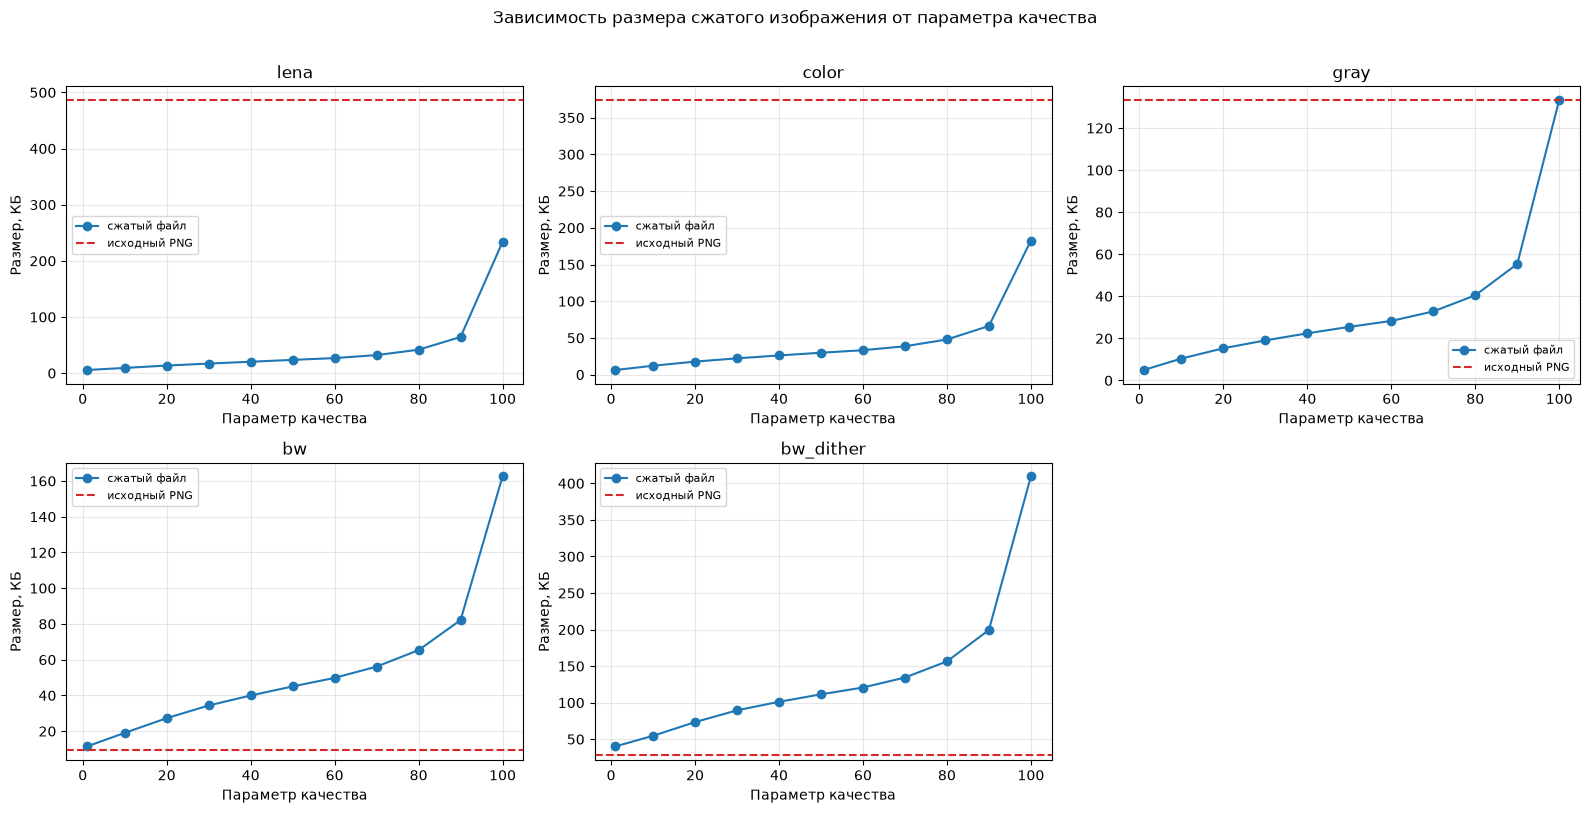

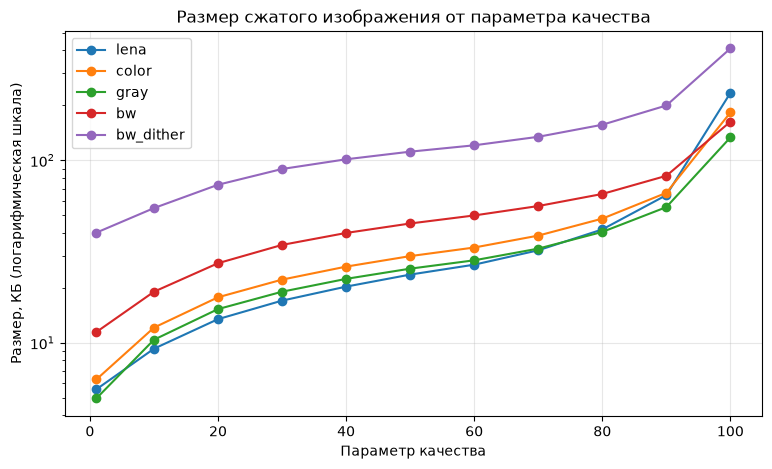

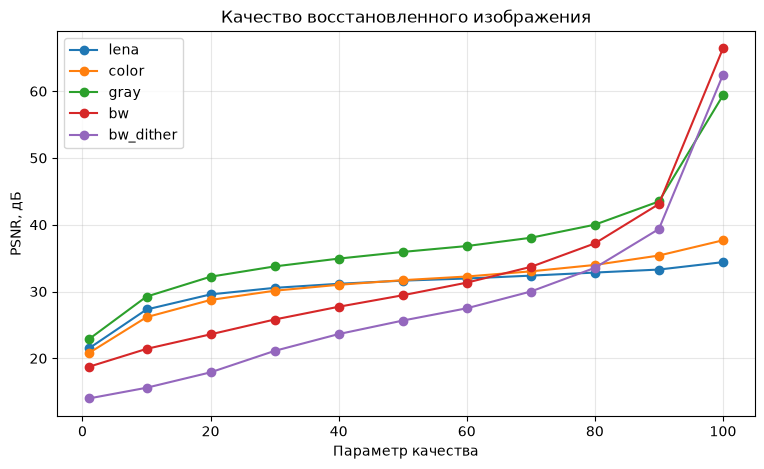

In [20]:
# ==================================================
# ГРАФИКИ: РАЗМЕР СЖАТОГО ИЗОБРАЖЕНИЯ ОТ КАЧЕСТВА
# ==================================================

names = list(TEST_FILES)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, name in zip(axes.ravel(), names):

    part = df_results[df_results["Изображение"] == name]

    ax.plot(part["Качество"], part["Размер, байт"] / 1024, marker="o", label="сжатый файл")
    ax.axhline(os.path.getsize(TEST_FILES[name]) / 1024, color="tab:red", linestyle="--", label="исходный PNG")

    ax.set_title(name)
    ax.set_xlabel("Параметр качества")
    ax.set_ylabel("Размер, КБ")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

for ax in axes.ravel()[len(names):]:
    ax.axis("off")

fig.suptitle("Зависимость размера сжатого изображения от параметра качества", y=1.01)

plt.tight_layout()
plt.show()

# все изображения на одном графике
plt.figure(figsize=(9, 5))

for name in names:

    part = df_results[df_results["Изображение"] == name]

    plt.plot(part["Качество"], part["Размер, байт"] / 1024, marker="o", label=name)

plt.yscale("log")
plt.xlabel("Параметр качества")
plt.ylabel("Размер, КБ (логарифмическая шкала)")
plt.title("Размер сжатого изображения от параметра качества")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# качество восстановленного изображения
plt.figure(figsize=(9, 5))

for name in names:

    part = df_results[df_results["Изображение"] == name]

    plt.plot(part["Качество"], part["PSNR, дБ"], marker="o", label=name)

plt.xlabel("Параметр качества")
plt.ylabel("PSNR, дБ")
plt.title("Качество восстановленного изображения")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

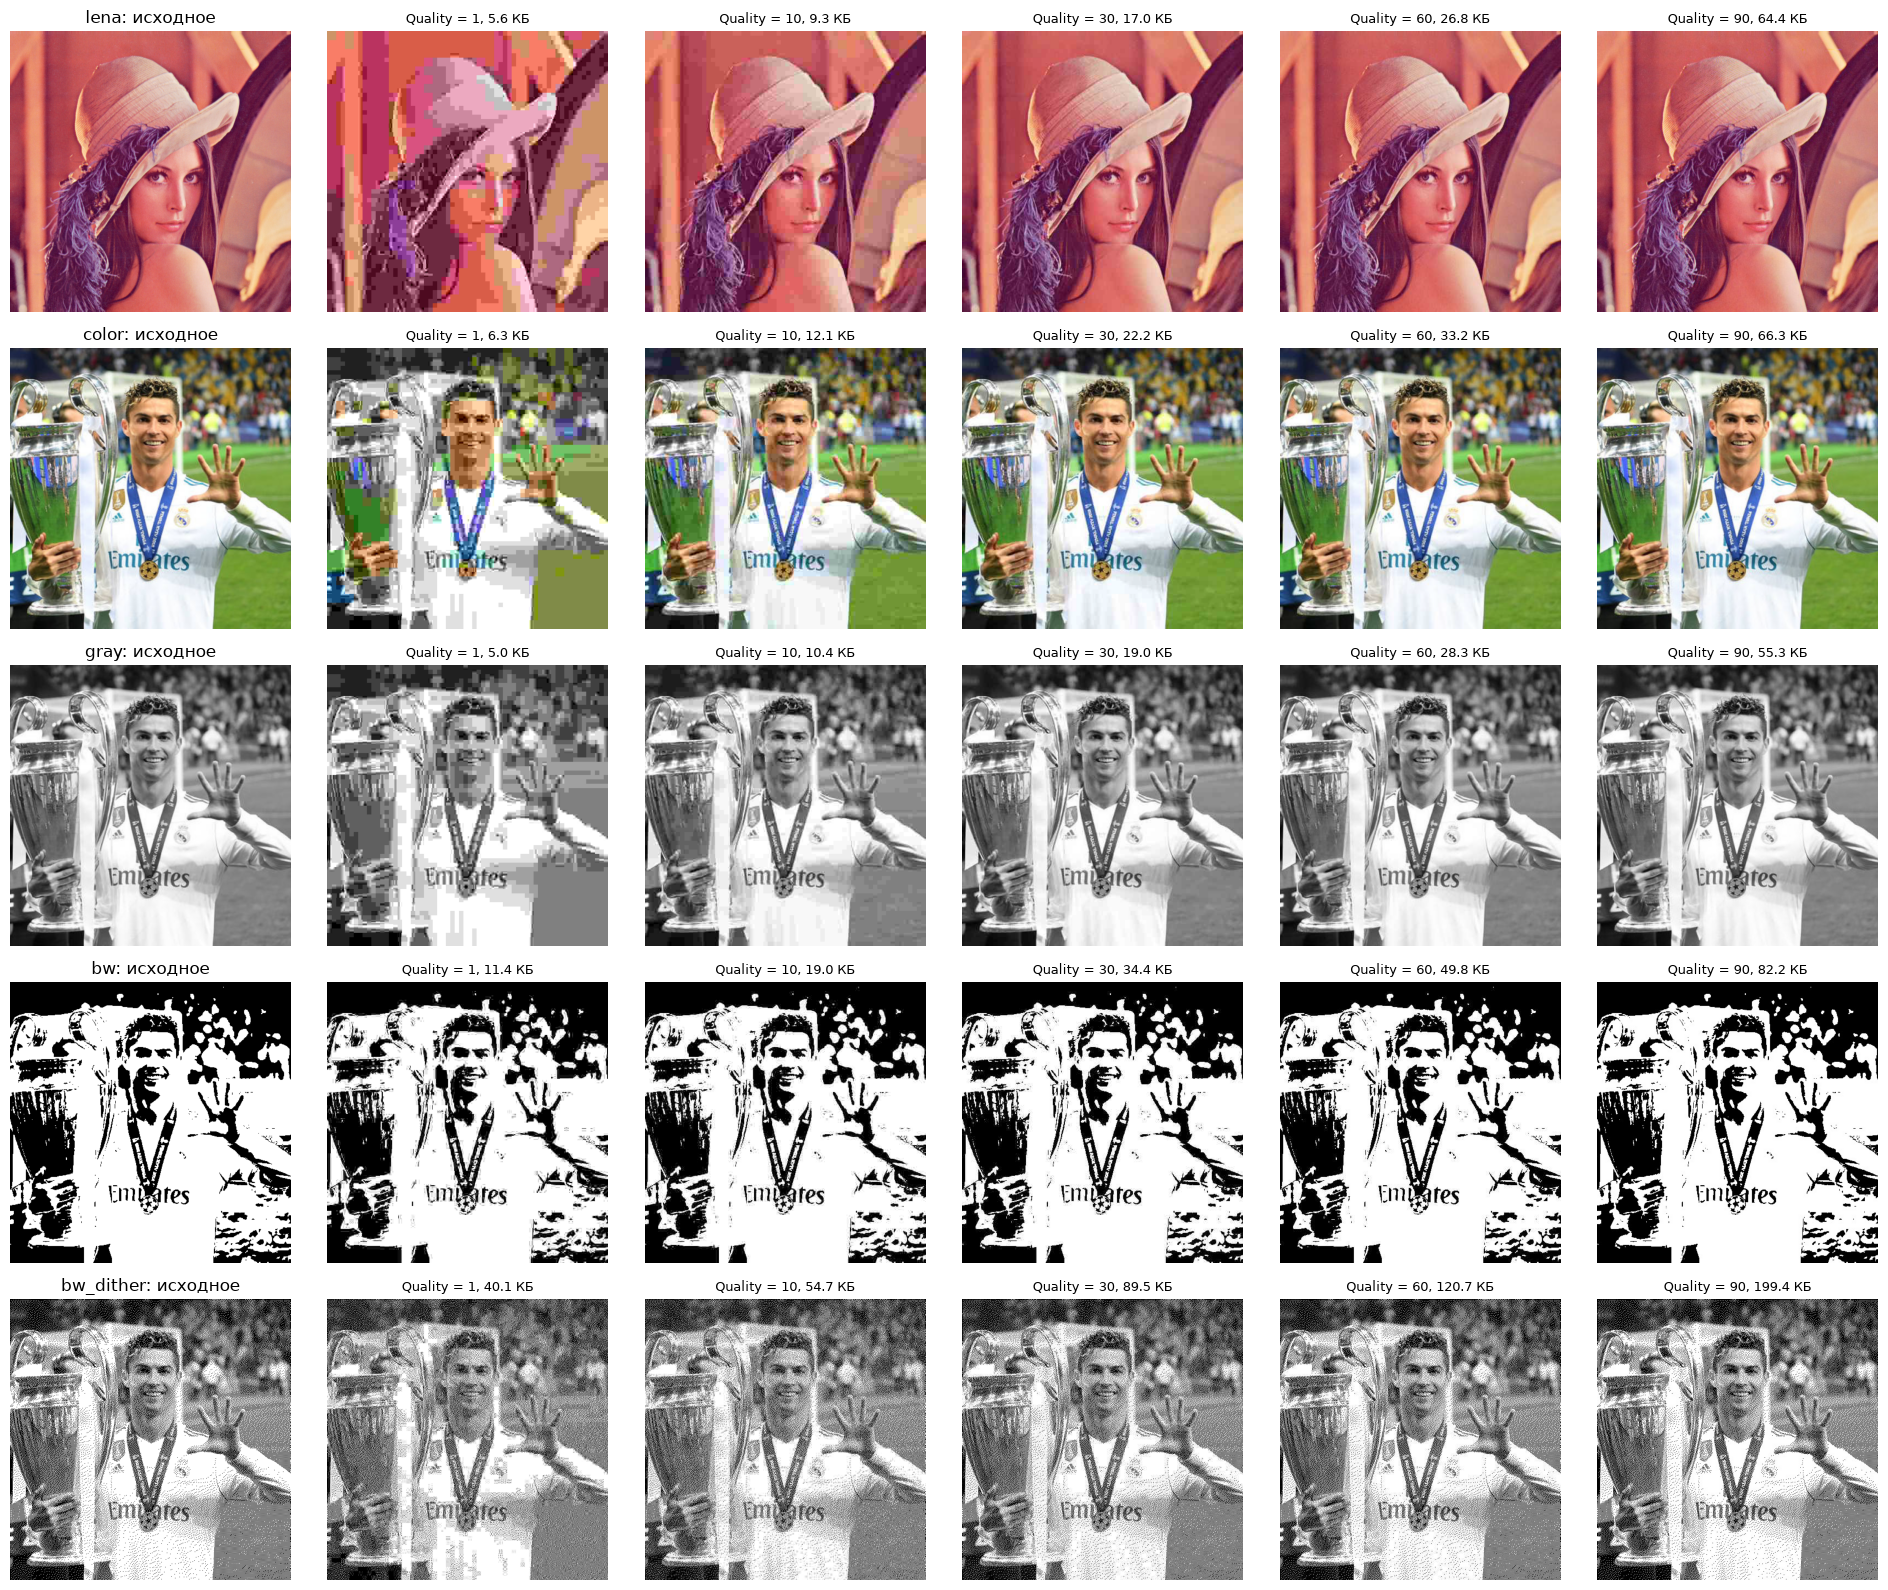

,Изображение,Качество,"Размер, байт",Коэфф. сжатия (RAW / сжатый),"PSNR, дБ","Сжатие, с","Распаковка, с"
0,lena,1,5691,138.19,21.48,0.1,0.1
1,lena,10,9503,82.76,27.31,0.1,0.1
2,lena,20,13797,57.00,29.57,0.1,0.1
3,lena,30,17429,45.12,30.55,0.1,0.2
4,lena,40,20794,37.82,31.16,0.1,0.2
5,lena,50,24202,32.49,31.63,0.1,0.1
6,lena,60,27427,28.67,31.95,0.1,0.2
7,lena,70,32880,23.92,32.38,0.2,0.1
8,lena,80,42782,18.38,32.84,0.1,0.2
9,lena,90,65925,11.93,33.29,0.2,0.2


In [21]:
# ==================================================
# ВОССТАНОВЛЕННЫЕ ИЗОБРАЖЕНИЯ (файлы лежат в папке restored)
# ==================================================

show_qualities = [1, 10, 30, 60, 90]

fig, axes = plt.subplots(len(names), len(show_qualities) + 1, figsize=(3.2 * (len(show_qualities) + 1), 3.2 * len(names)))

for row, name in enumerate(names):

    original = Image.open(TEST_FILES[name]).convert("RGB")

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(f"{name}: исходное")

    for col, quality in enumerate(show_qualities, start=1):

        size = df_results[(df_results["Изображение"] == name) & (df_results["Качество"] == quality)]["Размер, байт"].iloc[0]

        axes[row, col].imshow(Image.open(os.path.join(RESTORED_DIR, f"{name}_q{quality}.png")).convert("RGB"))
        axes[row, col].set_title(f"Quality = {quality}, {size / 1024:.1f} КБ", fontsize=9)

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

# ==================================================
# ТАБЛИЦА РЕЗУЛЬТАТОВ
# ==================================================

display(df_results)

# Вывод

_(Дополнить по результатам запуска.)_

Размер сжатого файла растёт с параметром качества: при малых значениях таблица квантования содержит большие числа, почти все AC коэффициенты обнуляются и в потоке остаются в основном DC разности, а при больших значениях сохраняется всё больше высокочастотных коэффициентов. Черно-белые изображения сжимаются лучше всего (…), цветные хуже (…). Качество восстановленного изображения оценивалось по PSNR и визуально: заметные блочные артефакты появляются при Quality ≈ …